# 界面重排：逐残基接触 + 肽滑移

配套执行器：`scripts/contacts_agent.py`

## 回答什么问题

"突变到底是**把界面破坏了**，还是**让肽换了个位置**？"

- 总接触数、buried SASA 只告诉你"总量变没变"
- **逐残基接触**告诉你"接触从哪些残基转移到了哪些残基"
- **肽质心滑移**告诉你"肽是不是真的平移了"

## 本项目实测结论（五变体）

| 变体 | 总接触占时率 | 核心残基(>0.5) | 质心滑移 | 界面模式 |
|---|---|---|---|---|
| WT | 15.79 | 16 | 0.20 nm | 基准 |
| Y262A | 15.80 | 16 | 0.17 nm | 等量重排（286/258 → 234/228/230） |
| S261E | 15.05 | 16 | 0.21 nm | 重排（286/258/228 → 264/279/263） |
| W282A | 14.48 | 13 | 0.29 nm | 重排 + 轻度减少 |
| E284P | 14.66 | 13 | 0.22 nm | 重排 + 轻度减少 |

**关键判读**：质心滑移都 <0.3 nm（肽没有大范围平移），但逐残基接触差异 Σ|Δ| ≈ 3.6–4.1——
说明变化是**界面内的接触重新分配**，不是"肽跑掉"。

In [1]:
import os, subprocess, sys
import pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

# ===================== CONFIG =====================
BASE     = "/root/autodl-tmp/GROMACS"
VARIANTS = ["WT", "Y262A", "W282A", "E284P", "S261E"]
REF      = "WT"
AGENT    = f"{BASE}/ANALYSIS/scripts/contacts_agent.py"
# ==================================================
print("agent:", AGENT, os.path.exists(AGENT))

agent: /root/autodl-tmp/GROMACS/ANALYSIS/scripts/contacts_agent.py True


In [2]:
cmd = [sys.executable, "-u", AGENT] + VARIANTS + ["--ref", REF]
print(" ".join(cmd))
r = subprocess.run(cmd, text=True, capture_output=True)
print(r.stdout[-2500:])
print(r.stderr[-500:] if r.returncode else "")

/root/autodl-tmp/miniconda3/bin/python -u /root/autodl-tmp/GROMACS/ANALYSIS/scripts/contacts_agent.py WT Y262A W282A E284P S261E --ref WT


[12:22:56] WT: COM sliding 0.20 nm (max 0.49) | |angle| 35.4 deg | frames 501
[12:23:00] Y262A: COM sliding 0.17 nm (max 0.57) | |angle| 41.0 deg | frames 501
[12:23:04] W282A: COM sliding 0.29 nm (max 0.65) | |angle| 33.9 deg | frames 501
[12:23:07] E284P: COM sliding 0.22 nm (max 0.64) | |angle| 28.8 deg | frames 501
[12:23:11] S261E: COM sliding 0.21 nm (max 0.66) | |angle| 73.6 deg | frames 501

=== interface rearrangement summary ===
variant  sum_occupancy  n_core_residues  mean_com_disp_nm  mean_abs_angle_deg  d_sum_occupancy_vs_ref
     WT      15.792415               16          0.204200           35.411067                0.000000
  Y262A      15.800399               16          0.169992           40.987341                0.007984
  W282A      14.477046               13          0.285131           33.944951               -1.315369
  E284P      14.664671               13          0.220988           28.762081               -1.127745
  S261E      15.045908               16        

variant  sum_occupancy  n_core_residues  mean_com_disp_nm  mean_abs_angle_deg  d_sum_occupancy_vs_ref
     WT      15.792415               16          0.204200           35.411067                0.000000
  Y262A      15.800399               16          0.169992           40.987341                0.007984
  W282A      14.477046               13          0.285131           33.944951               -1.315369
  E284P      14.664671               13          0.220988           28.762081               -1.127745
  S261E      15.045908               16          0.205114           73.565552               -0.746507


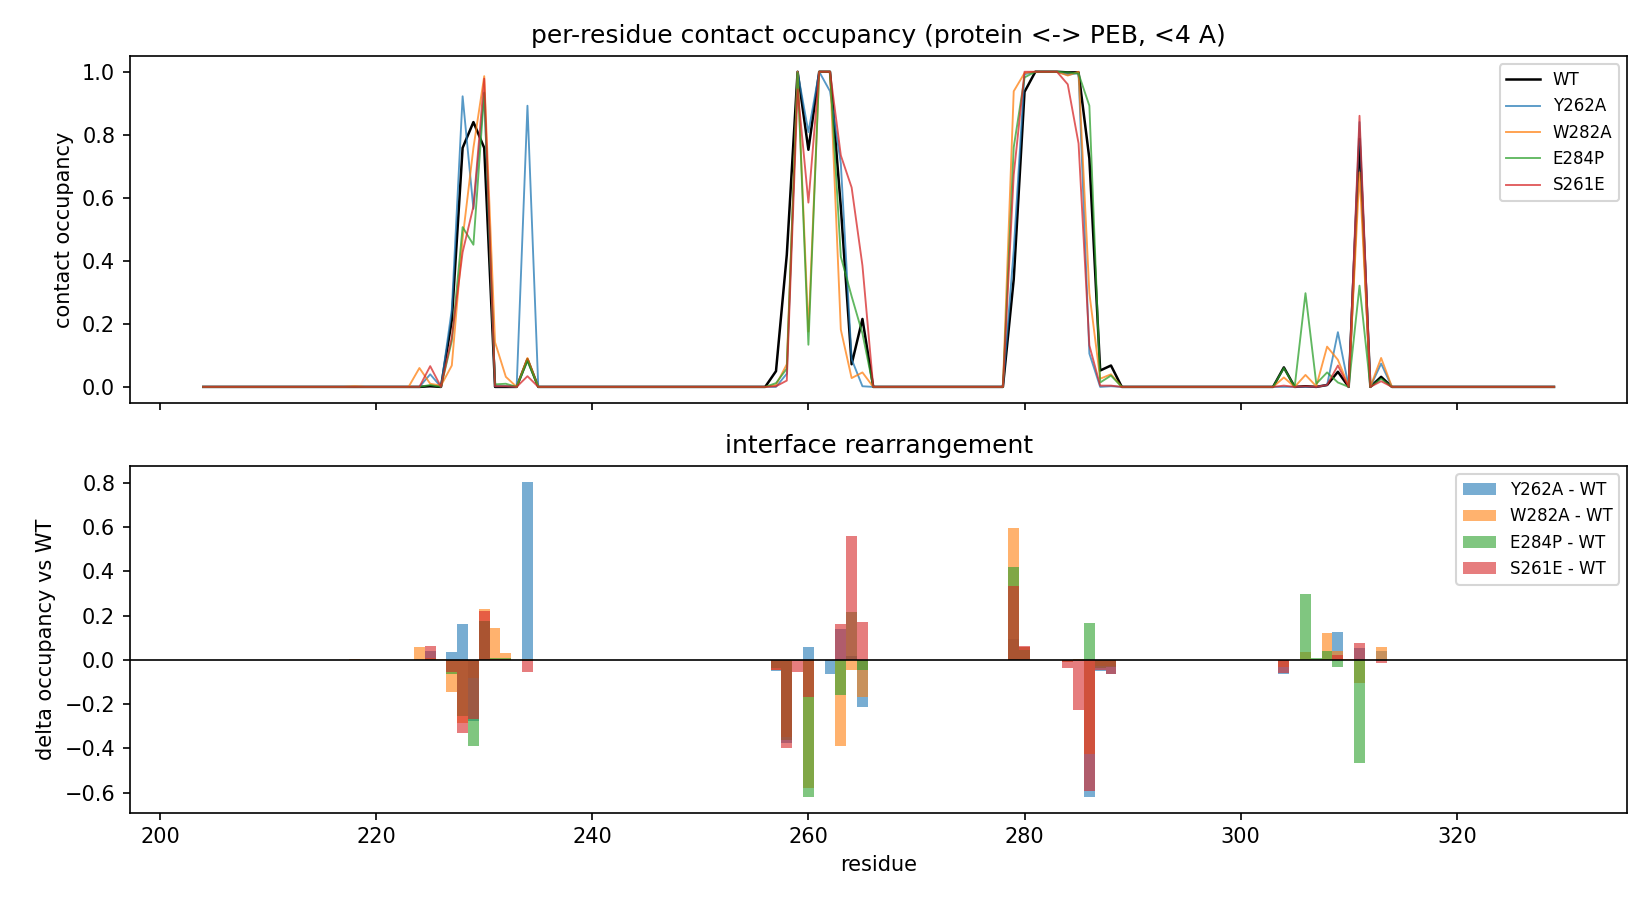

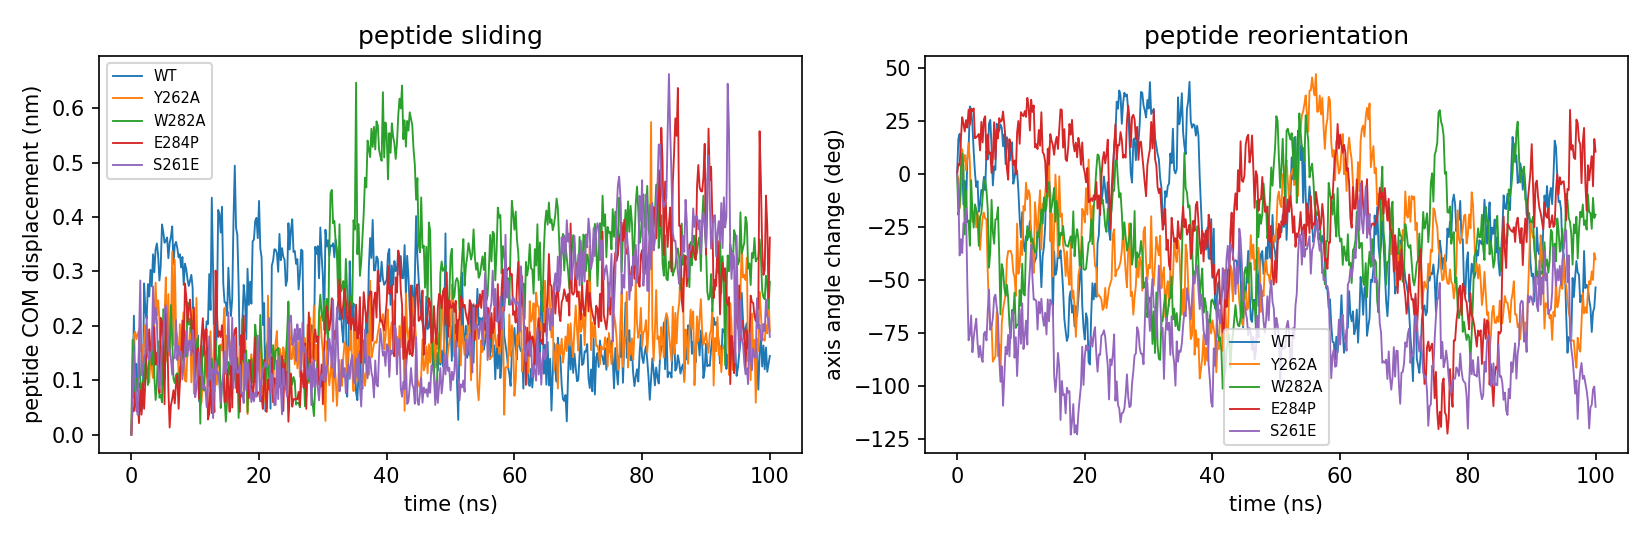

In [3]:
summary = pd.read_csv(f"{BASE}/ANALYSIS/peptide_motion_summary.csv")
print(summary.to_string(index=False))
display(Image(f"{BASE}/ANALYSIS/contacts_compare.png"))
display(Image(f"{BASE}/ANALYSIS/peptide_motion.png"))

## 怎么读这两张图

**上图（contacts_compare.png，上）**：每条曲线是一个变体的"逐残基接触占时率"。
峰的位置 = 与肽持续接触的残基；四个变体的峰位置整体一致（说明还在同一个沟槽），
但峰高/峰宽不同 → 接触的重新分配。

**上图（下）**：与 WT 的差值。**正柱 = 该残基在突变体里接触更多**（补偿），
负柱 = 接触更少。本项目里 Y262A 的 −286（−0.62）与 +234（+0.80）成对出现，
就是"肽滑到另一侧"的直接证据。

**peptide_motion.png**：左图是肽质心相对蛋白的位移（已做蛋白叠合，去掉了整体旋转/漂移），
右图是肽 N端→C端 向量相对蛋白 262→286 参考方向的转角。

## ⚠️ 关于"取向角"的可靠性

对**五肽**这种短而柔的分子，N→C 端向量的转角受**内部柔性**影响很大
（本项目实测 WT 自身就有 ±35° 的涨落），**不能当作"刚性重定向"的证据**。

> 结论：**以逐残基接触差（`contacts_compare.csv`）作为主要证据，取向角只作辅助参考。**
> 要严格讨论取向，应使用基于多个片段的准刚体拟合（如 PCA 主轴 + 结构域定义）。

## 与结构/能量指标的关系

| 指标 | 现象 | 解释 |
|---|---|---|
| 接触总数 | 变化 ≤8% | 界面规模基本不变 |
| **逐残基接触** | Σ\|Δ\| ≈ 3.6–4.1 | **接触重新分配**（主要结论） |
| 肽质心滑移 | <0.3 nm | 没有大范围平移 |
| MM/GBSA | Y262A −2.1 kcal/mol（噪声内） | 重排后相互作用能相当，与"1–3"自洽 |
| ITC（Y262A） | 不结合 | 界面重排不足以解释，需解离动力学（PMF） |

**一句话**：结构层面看到的是"**换了接触**"，不是"少了接触"；这也正是 MM-GBSA 没显示出减弱的原因。